<a href="https://colab.research.google.com/github/kvikaee/deep-learning/blob/main/%D0%93%D0%9E_%D0%9B%D0%A04_%D0%9A%D0%BE%D1%88%D1%83%D1%80%D0%B8%D0%BD%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В этой лабораторной работе ваша задача состоит в ознакомлении с GAN.


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)


device: cuda


Первая задача - это простая отработка генеративной архитектуры. Необходимо, взяв за основу датасет https://www.kaggle.com/datasets/zalando-research/fashionmnist, получить на выходе сети подобные входным изображения. Архитектуру генератора и дискриминатора подбирайте самостоятельно.

In [ ]:
# параметры первой задачи
batch_size = 128
latent_dim = 100
image_size = 28
epochs_fashion = 15

fashion_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

fashion_train = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=fashion_transform
)

fashion_loader = DataLoader(
    fashion_train,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

class FashionGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 28 * 28),
            nn.Tanh()
        )

    def forward(self, z):
        x = self.net(z)
        return x.view(-1, 1, 28, 28)


class FashionDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Linear(256, 1)
        )

    def forward(self, x):
        return self.net(x)


generator_fashion = FashionGenerator(latent_dim).to(device)
discriminator_fashion = FashionDiscriminator().to(device)

criterion_gan = nn.BCEWithLogitsLoss()

optimizer_g_fashion = torch.optim.Adam(
    generator_fashion.parameters(),
    lr=2e-4,
    betas=(0.5, 0.999)
)

optimizer_d_fashion = torch.optim.Adam(
    discriminator_fashion.parameters(),
    lr=2e-4,
    betas=(0.5, 0.999)
)

print(generator_fashion)
print(discriminator_fashion)


100%|██████████| 26.4M/26.4M [00:02<00:00, 11.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.18MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 15.3MB/s]


FashionGenerator(
  (net): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Linear(in_features=512, out_features=1024, bias=True)
    (6): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Linear(in_features=1024, out_features=784, bias=True)
    (9): Tanh()
  )
)
FashionDiscriminator(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): LeakyReLU(negative_slope=0.2, inplace=T

epoch 01/15 | d_loss: 0.5906 | g_loss: 1.0591
epoch 02/15 | d_loss: 0.5853 | g_loss: 1.2138
epoch 03/15 | d_loss: 0.6288 | g_loss: 1.0370
epoch 04/15 | d_loss: 0.6491 | g_loss: 0.9418
epoch 05/15 | d_loss: 0.6628 | g_loss: 0.8697
epoch 06/15 | d_loss: 0.6587 | g_loss: 0.8802
epoch 07/15 | d_loss: 0.6624 | g_loss: 0.8564
epoch 08/15 | d_loss: 0.6647 | g_loss: 0.8522
epoch 09/15 | d_loss: 0.6674 | g_loss: 0.8369
epoch 10/15 | d_loss: 0.6664 | g_loss: 0.8435
epoch 11/15 | d_loss: 0.6715 | g_loss: 0.8149
epoch 12/15 | d_loss: 0.6704 | g_loss: 0.8153
epoch 13/15 | d_loss: 0.6694 | g_loss: 0.8234
epoch 14/15 | d_loss: 0.6697 | g_loss: 0.8255
epoch 15/15 | d_loss: 0.6709 | g_loss: 0.8160


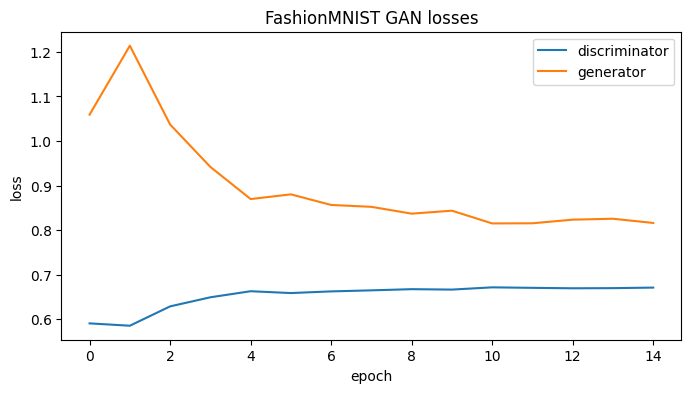

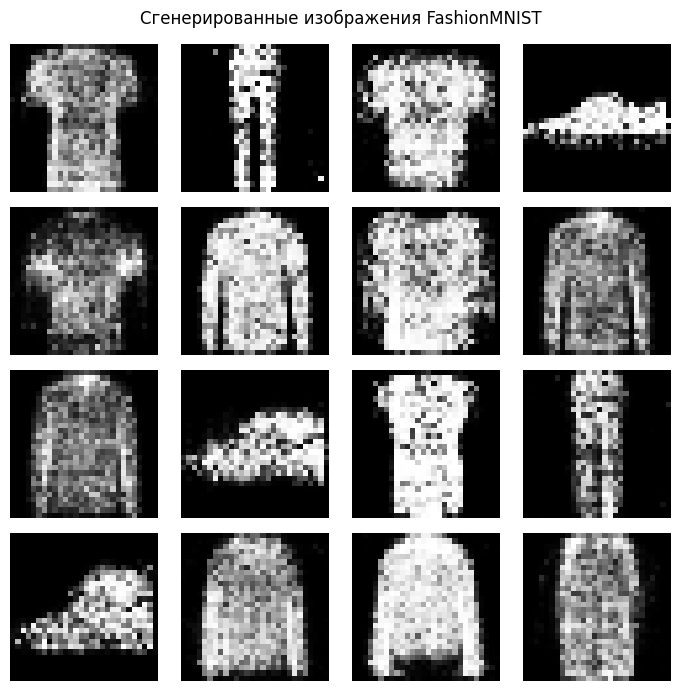

In [ ]:
g_losses = []
d_losses = []

for epoch in range(epochs_fashion):
    generator_fashion.train()
    discriminator_fashion.train()

    g_epoch_loss = 0
    d_epoch_loss = 0

    for real_images, _ in fashion_loader:
        real_images = real_images.to(device)
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # обучение дискриминатора
        optimizer_d_fashion.zero_grad()

        real_logits = discriminator_fashion(real_images)
        d_real_loss = criterion_gan(real_logits, real_labels)

        z = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator_fashion(z)

        fake_logits = discriminator_fashion(fake_images.detach())
        d_fake_loss = criterion_gan(fake_logits, fake_labels)

        d_loss = (d_real_loss + d_fake_loss) / 2
        d_loss.backward()
        optimizer_d_fashion.step()

        # обучение генератора
        optimizer_g_fashion.zero_grad()

        fake_logits = discriminator_fashion(fake_images)
        g_loss = criterion_gan(fake_logits, real_labels)

        g_loss.backward()
        optimizer_g_fashion.step()

        d_epoch_loss += d_loss.item()
        g_epoch_loss += g_loss.item()

    d_epoch_loss /= len(fashion_loader)
    g_epoch_loss /= len(fashion_loader)

    d_losses.append(d_epoch_loss)
    g_losses.append(g_epoch_loss)

    print(
        f"epoch {epoch + 1:02d}/{epochs_fashion} | "
        f"d_loss: {d_epoch_loss:.4f} | "
        f"g_loss: {g_epoch_loss:.4f}"
    )

plt.figure(figsize=(8, 4))
plt.plot(d_losses, label="discriminator")
plt.plot(g_losses, label="generator")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("FashionMNIST GAN losses")
plt.legend()
plt.show()

generator_fashion.eval()

with torch.no_grad():
    z = torch.randn(16, latent_dim, device=device)
    generated = generator_fashion(z).cpu()
    generated = (generated + 1) / 2

fig, axes = plt.subplots(4, 4, figsize=(7, 7))

for ax, image in zip(axes.ravel(), generated):
    ax.imshow(image.squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Сгенерированные изображения FashionMNIST")
plt.tight_layout()
plt.show()


В процессе обучения ошибка генератора постепенно уменьшается и стабилизируется примерно на уровне 0.8, а ошибка дискриминатора находится около 0.67. Это показывает, что обучение вышло в относительно стабильное состояние: генератор стал лучше создавать изображения, а дискриминатору стало сложнее отличать их от реальных.

После обучения генератор создаёт изображения, в которых уже хорошо различимы предметы одежды: обувь, брюки, футболки и верхняя одежда. Изображения остаются шумными и нечёткими, но основные формы объектов модель освоила.

Зачача №2 сосстоит в повышении качества изображения. Предлагается использовать две разные архитектуры: обычный автоэнкодер и генеративно-состязательную сеть. Здесь предлагается выбрать любой датасет, состоящий из изображений желательно в трех цветовых каналах, но можно взять и черно-белые, однако в любом случае исходные изображения должны быть в разрешении хотя бы 300х300 и представлять собой композиции (иначе говоря - быть "сложными". Подойдут, например, любые фотографии тех же кошек/собак). Датасет здесь состоит из изображений исходного размера, которые пойдут на выход, и их сжатых копий, которые пойдут на вход сети (просто скукожьте исходники с помощью resize в 2 или 4 раза). Отделите часть датасета для теста (не валидации!) и после обучения нейронной сети примените её к сжатым изображениям тестовой выборки. Результат применения выведете на экран. Не обязательно брать изображения в высоком разрешении,

Автоэнкодер:

100%|██████████| 792M/792M [00:37<00:00, 21.3MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.63MB/s]


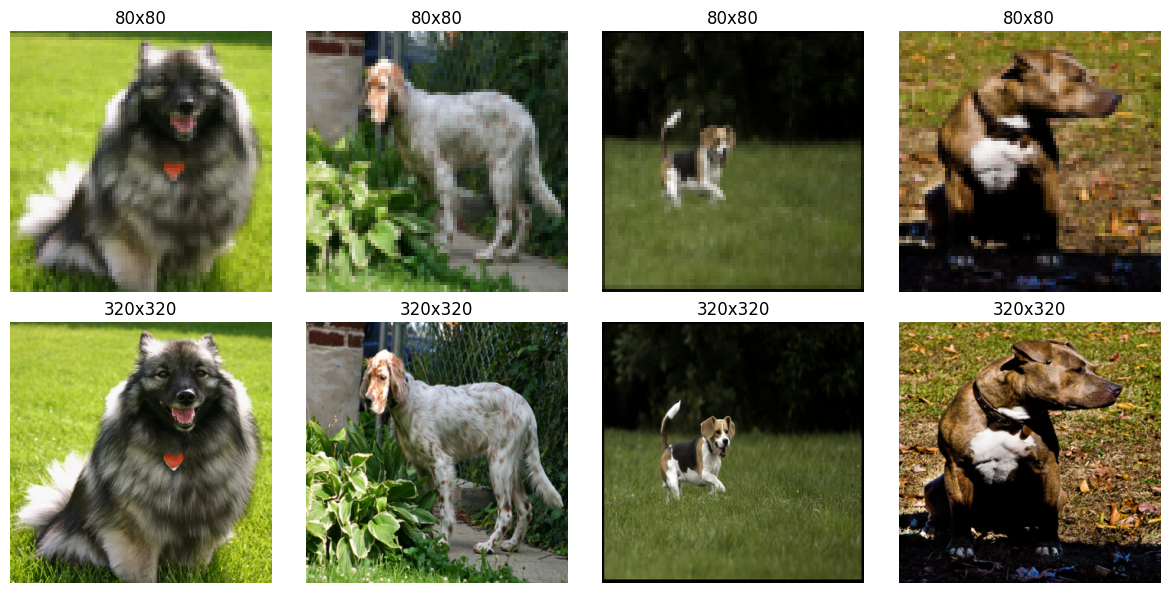

In [ ]:
# изображения будут приводиться к 320x320,
# а на вход сети поступят их уменьшенные копии 80x80
high_size = 320
low_size = 80

max_train_images = 1200
max_test_images = 200
batch_size_sr = 8

high_transform = transforms.Compose([
    transforms.Resize((high_size, high_size)),
    transforms.ToTensor()
])

pets_train_full = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True,
    transform=high_transform
)

pets_test_full = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True,
    transform=high_transform
)

train_count = min(max_train_images, len(pets_train_full))
test_count = min(max_test_images, len(pets_test_full))

pets_train = Subset(pets_train_full, range(train_count))
pets_test = Subset(pets_test_full, range(test_count))


class SuperResolutionDataset(torch.utils.data.Dataset):
    def __init__(self, subset, low_size=80):
        self.subset = subset
        self.low_size = low_size

    def __len__(self):
        return len(self.subset)

    def __getitem__(self, index):
        high_image, _ = self.subset[index]

        # уменьшаем исходное изображение в 4 раза
        low_image = transforms.functional.resize(
            high_image,
            [self.low_size, self.low_size],
            antialias=True
        )

        return low_image, high_image


sr_train = SuperResolutionDataset(pets_train, low_size)
sr_test = SuperResolutionDataset(pets_test, low_size)

sr_train_loader = DataLoader(
    sr_train,
    batch_size=batch_size_sr,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

sr_test_loader = DataLoader(
    sr_test,
    batch_size=batch_size_sr,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

low_images, high_images = next(iter(sr_train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(low_images[i].permute(1, 2, 0))
    axes[0, i].set_title("80x80")
    axes[0, i].axis("off")

    axes[1, i].imshow(high_images[i].permute(1, 2, 0))
    axes[1, i].set_title("320x320")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


После уменьшения разрешения с 320×320 до 80×80 теряется часть мелких деталей и снижается резкость изображения. При этом основные объекты, цвета и общая структура изображения сохраняются.

epoch 01/5 | ae_loss: 0.1060
epoch 02/5 | ae_loss: 0.0644
epoch 03/5 | ae_loss: 0.0573
epoch 04/5 | ae_loss: 0.0510
epoch 05/5 | ae_loss: 0.0492


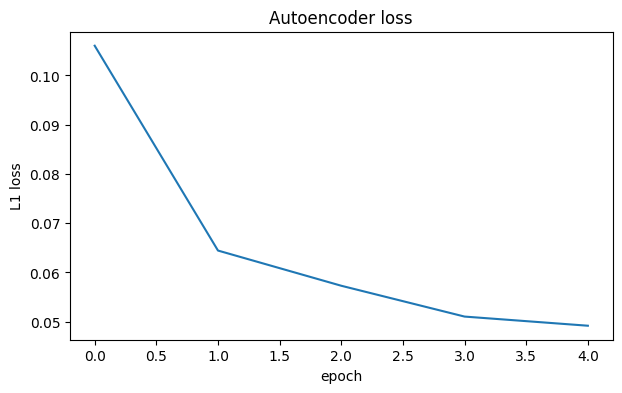

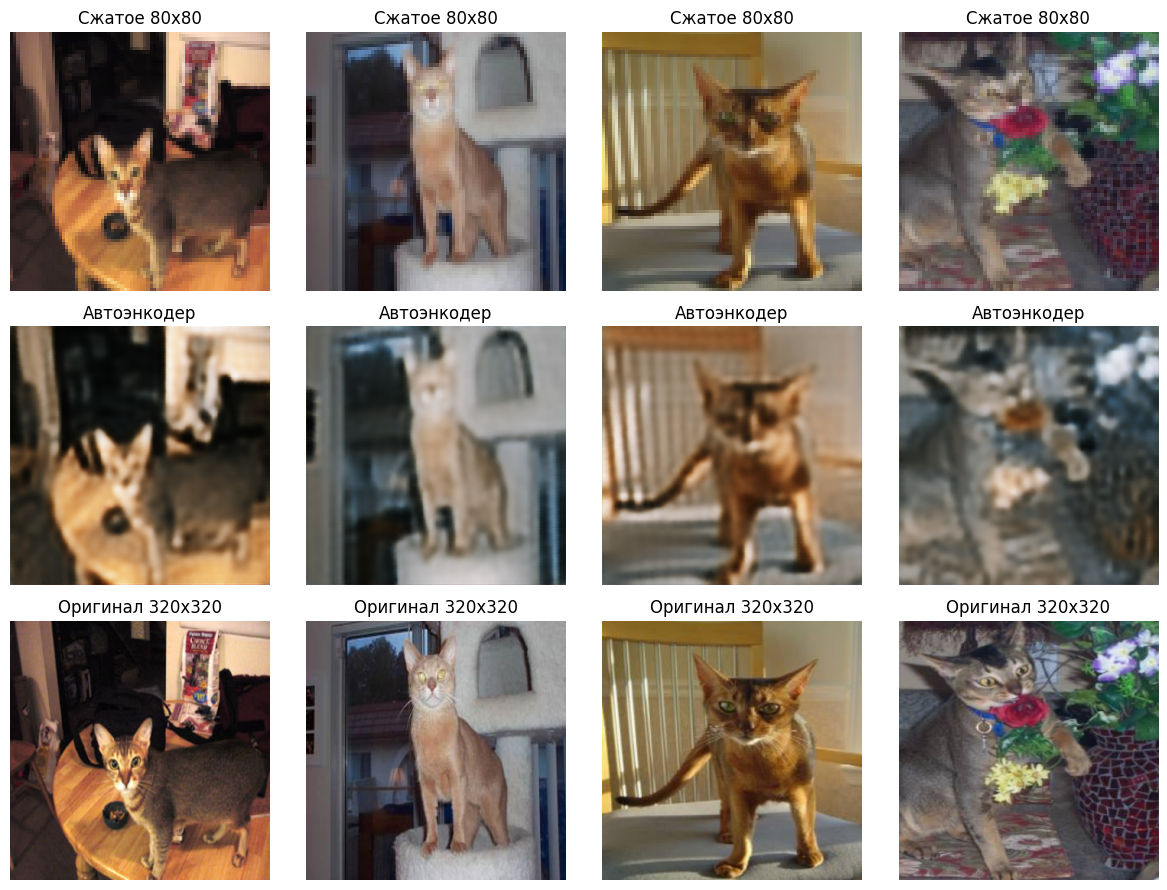

In [ ]:
class SuperResolutionAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, 3, stride=1, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, 4, stride=2, padding=1),
            nn.ReLU(inplace=True)
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 3, 3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        return self.decoder(x)


autoencoder = SuperResolutionAutoencoder().to(device)

criterion_ae = nn.L1Loss()
optimizer_ae = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)

epochs_ae = 5
ae_losses = []

for epoch in range(epochs_ae):
    autoencoder.train()
    epoch_loss = 0

    for low_images, high_images in sr_train_loader:
        low_images = low_images.to(device)
        high_images = high_images.to(device)

        optimizer_ae.zero_grad()

        restored_images = autoencoder(low_images)
        loss = criterion_ae(restored_images, high_images)

        loss.backward()
        optimizer_ae.step()

        epoch_loss += loss.item()

    epoch_loss /= len(sr_train_loader)
    ae_losses.append(epoch_loss)

    print(
        f"epoch {epoch + 1:02d}/{epochs_ae} | "
        f"ae_loss: {epoch_loss:.4f}"
    )

plt.figure(figsize=(7, 4))
plt.plot(ae_losses)
plt.xlabel("epoch")
plt.ylabel("L1 loss")
plt.title("Autoencoder loss")
plt.show()

autoencoder.eval()

low_test, high_test = next(iter(sr_test_loader))

with torch.no_grad():
    ae_result = autoencoder(low_test.to(device)).cpu()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i in range(4):
    axes[0, i].imshow(low_test[i].permute(1, 2, 0))
    axes[0, i].set_title("Сжатое 80x80")
    axes[0, i].axis("off")

    axes[1, i].imshow(ae_result[i].permute(1, 2, 0).clamp(0, 1))
    axes[1, i].set_title("Автоэнкодер")
    axes[1, i].axis("off")

    axes[2, i].imshow(high_test[i].permute(1, 2, 0))
    axes[2, i].set_title("Оригинал 320x320")
    axes[2, i].axis("off")

plt.tight_layout()
plt.show()


Автоэнкодер успешно увеличивает изображения с 80×80 до 320×320 и восстанавливает основные формы и цвета. Однако результат остаётся достаточно размытым, так как модель хорошо восстанавливает общую структуру, но хуже передаёт мелкие детали и текстуры.

GAN:

epoch 01/5 | d_loss: 0.4773 | g_loss: 9.2439
epoch 02/5 | d_loss: 0.2655 | g_loss: 7.7617
epoch 03/5 | d_loss: 0.1225 | g_loss: 8.2479
epoch 04/5 | d_loss: 0.2041 | g_loss: 8.1631
epoch 05/5 | d_loss: 0.1120 | g_loss: 8.3172


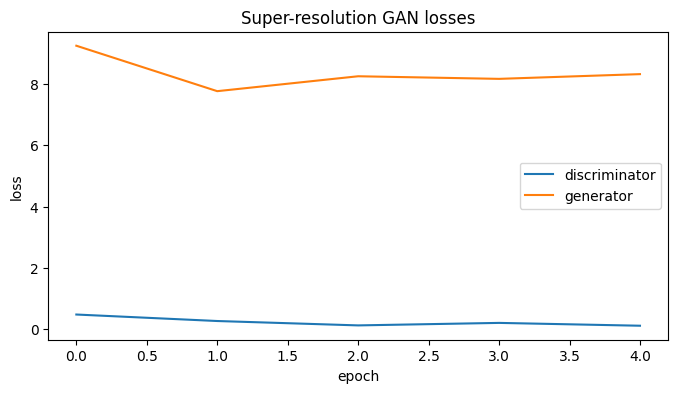

In [ ]:
class SRGenerator(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 9, padding=4),
            nn.PReLU(),

            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.PReLU(),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.PReLU(),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.PReLU(),

            nn.Conv2d(32, 3, 9, padding=4),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


class SRDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(128, 256, 4, stride=2, padding=1),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(256, 512, 4, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(512, 512, 4, stride=2, padding=1),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Linear(512, 1)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


generator_sr = SRGenerator().to(device)
discriminator_sr = SRDiscriminator().to(device)

criterion_adv = nn.BCEWithLogitsLoss()
criterion_content = nn.L1Loss()

optimizer_g_sr = torch.optim.Adam(
    generator_sr.parameters(),
    lr=1e-4,
    betas=(0.5, 0.999)
)

optimizer_d_sr = torch.optim.Adam(
    discriminator_sr.parameters(),
    lr=1e-4,
    betas=(0.5, 0.999)
)

epochs_sr_gan = 5
lambda_content = 100

g_sr_losses = []
d_sr_losses = []

for epoch in range(epochs_sr_gan):
    generator_sr.train()
    discriminator_sr.train()

    g_epoch_loss = 0
    d_epoch_loss = 0

    for low_images, high_images in sr_train_loader:
        low_images = low_images.to(device)
        high_images = high_images.to(device)

        current_batch_size = low_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # обучение дискриминатора
        optimizer_d_sr.zero_grad()

        fake_images = generator_sr(low_images)

        real_logits = discriminator_sr(high_images)
        fake_logits = discriminator_sr(fake_images.detach())

        d_real_loss = criterion_adv(real_logits, real_labels)
        d_fake_loss = criterion_adv(fake_logits, fake_labels)

        d_loss = (d_real_loss + d_fake_loss) / 2
        d_loss.backward()
        optimizer_d_sr.step()

        # обучение генератора
        optimizer_g_sr.zero_grad()

        fake_images = generator_sr(low_images)
        fake_logits = discriminator_sr(fake_images)

        adversarial_loss = criterion_adv(fake_logits, real_labels)
        content_loss = criterion_content(fake_images, high_images)

        g_loss = adversarial_loss + lambda_content * content_loss

        g_loss.backward()
        optimizer_g_sr.step()

        d_epoch_loss += d_loss.item()
        g_epoch_loss += g_loss.item()

    d_epoch_loss /= len(sr_train_loader)
    g_epoch_loss /= len(sr_train_loader)

    d_sr_losses.append(d_epoch_loss)
    g_sr_losses.append(g_epoch_loss)

    print(
        f"epoch {epoch + 1:02d}/{epochs_sr_gan} | "
        f"d_loss: {d_epoch_loss:.4f} | "
        f"g_loss: {g_epoch_loss:.4f}"
    )

plt.figure(figsize=(8, 4))
plt.plot(d_sr_losses, label="discriminator")
plt.plot(g_sr_losses, label="generator")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("Super-resolution GAN losses")
plt.legend()
plt.show()


Ошибка дискриминатора быстро уменьшается почти до нуля, тогда как ошибка генератора остаётся значительно выше. Это означает, что дискриминатор научился достаточно легко различать реальные и восстановленные изображения. Несмотря на дисбаланс обучения, генератор смог улучшить визуальную резкость изображений по сравнению с автоэнкодером.

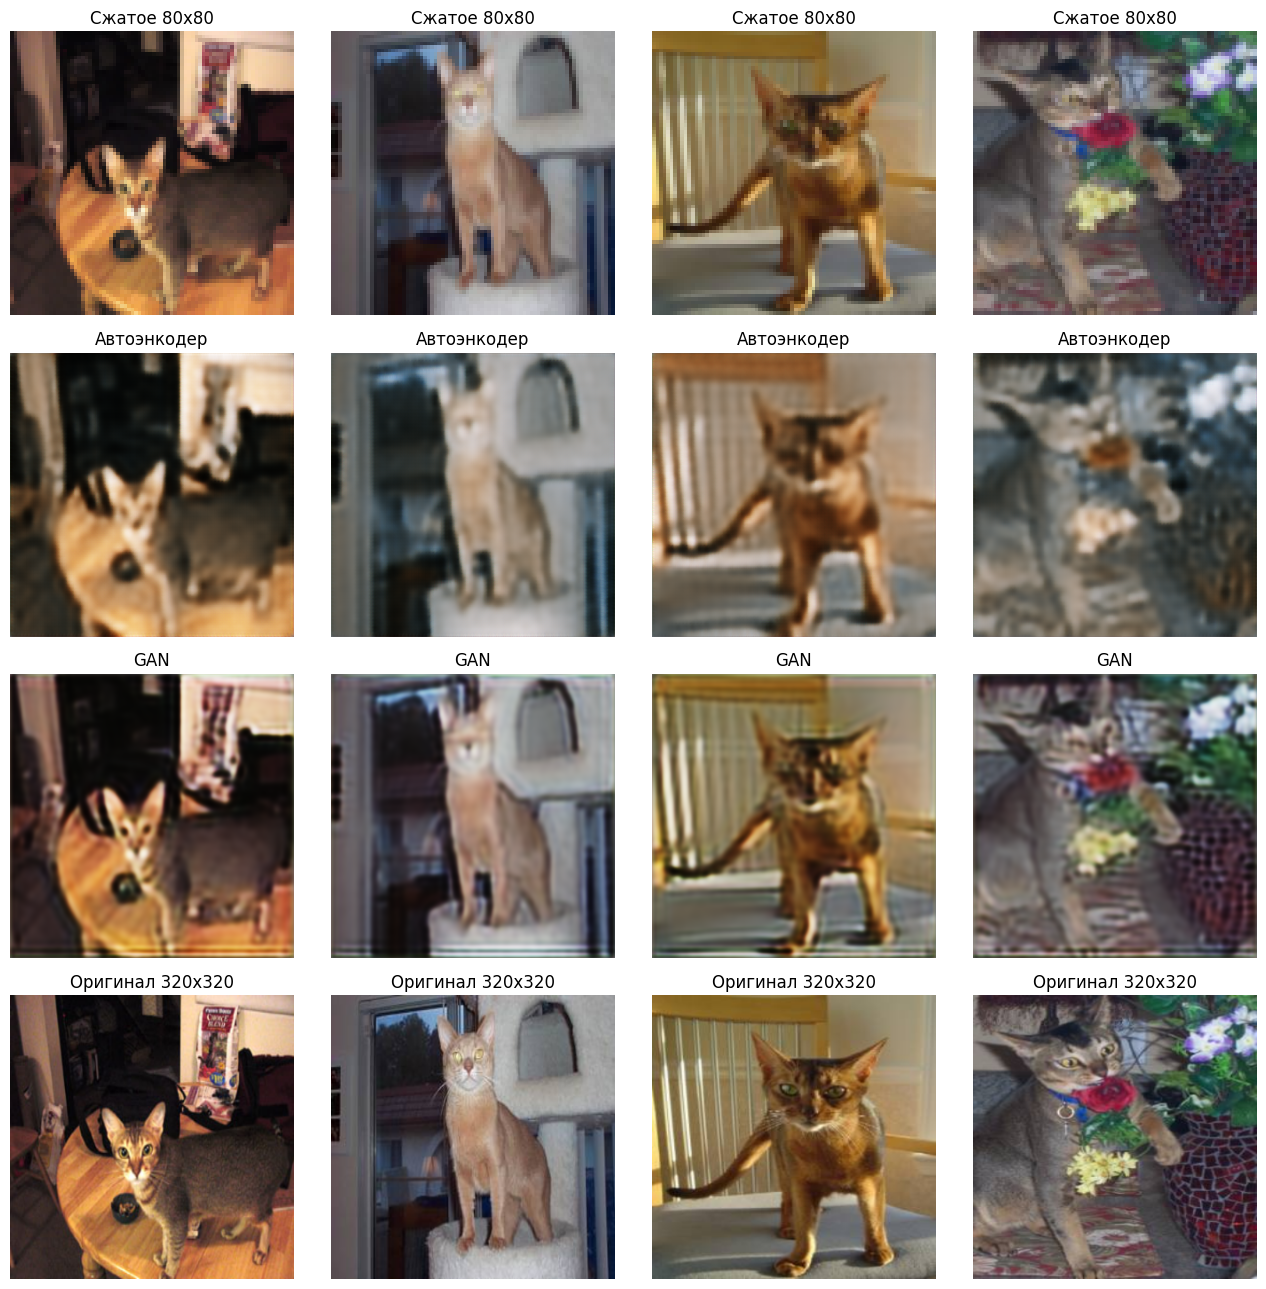

MAE автоэнкодера: 0.0448
MAE GAN:          0.0369


In [ ]:
generator_sr.eval()
autoencoder.eval()

low_test, high_test = next(iter(sr_test_loader))

with torch.no_grad():
    ae_result = autoencoder(low_test.to(device)).cpu()
    gan_result = generator_sr(low_test.to(device)).cpu()

fig, axes = plt.subplots(4, 4, figsize=(13, 13))

for i in range(4):
    axes[0, i].imshow(low_test[i].permute(1, 2, 0))
    axes[0, i].set_title("Сжатое 80x80")
    axes[0, i].axis("off")

    axes[1, i].imshow(ae_result[i].permute(1, 2, 0).clamp(0, 1))
    axes[1, i].set_title("Автоэнкодер")
    axes[1, i].axis("off")

    axes[2, i].imshow(gan_result[i].permute(1, 2, 0).clamp(0, 1))
    axes[2, i].set_title("GAN")
    axes[2, i].axis("off")

    axes[3, i].imshow(high_test[i].permute(1, 2, 0))
    axes[3, i].set_title("Оригинал 320x320")
    axes[3, i].axis("off")

plt.tight_layout()
plt.show()

ae_mae = torch.mean(torch.abs(ae_result - high_test)).item()
gan_mae = torch.mean(torch.abs(gan_result - high_test)).item()

print(f"MAE автоэнкодера: {ae_mae:.4f}")
print(f"MAE GAN:          {gan_mae:.4f}")


Оба подхода восстанавливают изображение высокого разрешения, однако результаты отличаются. Автоэнкодер создаёт более сглаженные и размытые изображения, тогда как GAN формирует более выраженные границы и детали. При этом у GAN местами появляются искусственные артефакты, которых нет на оригинале.
